# Clase 1.2: Exploración de un corpus

En el notebook 1.1 cortamos el texto en tokens. Ahora los contamos. Tomamos dos colecciones de textos en español, noticias de BBC Mundo y chistes, y les hacemos las preguntas que conviene hacerle a cualquier corpus antes de entrenar un modelo: cuánto texto tiene, cuántas palabras distintas usa, cuáles se repiten más y cuáles distinguen a un documento de los demás.

**Objetivos de la clase**

- Medir el tamaño de un corpus, el de su vocabulario y su diversidad léxica.
- Reconocer las leyes de Heaps y de Zipf en datos reales.
- Resumir un corpus con nubes de palabras, con y sin stopwords.
- Encontrar las palabras distintivas de un documento con TF-IDF.
- Mirar una palabra en su contexto (concordancia) y las palabras que van juntas (bigramas).

## 0. Preparación

In [1]:
# Colab no trae wordcloud. No actualizamos numpy ni pandas: rompe Colab.
!pip install -q wordcloud

## 1. Dos corpus en español

El primer corpus son 4.000 noticias de BBC Mundo, tomadas de XL-Sum, un conjunto de noticias con su resumen en 44 idiomas. El segundo es una colección de chistes. Los elegimos distintos a propósito: ¿en qué se va a notar la diferencia cuando los contemos?

In [2]:
import datasets

# Descargamos 3.000 noticias de entrenamiento y 1.000 de prueba, en la copia
# en formato parquet del dataset (no depende de la versión de `datasets`)
base = "hf://datasets/csebuetnlp/xlsum@refs/convert/parquet/spanish"
noticias = datasets.load_dataset(
    "parquet",
    data_files={
        "train": f"{base}/train/*.parquet",
        "test": f"{base}/test/*.parquet",
    },
    split="train[:3000]+test[:1000]",
)
noticias

Dataset({
    features: ['id', 'url', 'title', 'summary', 'text'],
    num_rows: 4000
})

Cada documento es una noticia. Miremos el comienzo de una, que va a volver más adelante:

In [3]:
noticia = noticias[1597]
print(noticia["title"])
print()
print(noticia["text"][:600], "[...]")

La bicicleta chilena antirrobo que nació de un mal recuerdo

Junto a Cristóbal Cabello y Juan José Monsalve, chilenos, amigos y compañeros de Ingeniería Civil Industrial, Eggers ideó una bicicleta que también es candado. "La única manera de robarla es romperla, dejándola inutilizable, desincentivando el robo de ésta", explican en la página web de su proyecto. Los tres estudiantes, de la Universidad Adolfo Ibáñez de Chile, llevan dos años trabajando en lo que inicialmente empezó como un trabajo de curso. "Se planteó resolver un problema de la sociedad y nosotros decidimos resolver el problema de la bicicleta y la seguridad. Haciendo una lluvia de ideas s [...]


Normalizamos y tokenizamos como en el notebook 1.1: todo en minúsculas, solo letras, sin tildes, y separamos por espacios.

In [4]:
import re

def normalize(text: str, remove_tildes: bool = True) -> str:
    # Minúsculas, y todo lo que no es letra pasa a ser un espacio
    text = text.lower()
    text = re.sub(r"[^a-zñüáéíóú]", " ", text)
    if remove_tildes:
        for con_tilde, sin_tilde in zip("áéíóú", "aeiou"):
            text = text.replace(con_tilde, sin_tilde)
    return text


tokens_noticias = [normalize(texto).split() for texto in noticias["text"]]
tokens_noticias[1597][:15]

['junto',
 'a',
 'cristobal',
 'cabello',
 'y',
 'juan',
 'jose',
 'monsalve',
 'chilenos',
 'amigos',
 'y',
 'compañeros',
 'de',
 'ingenieria',
 'civil']

El segundo corpus:

In [5]:
chistes = datasets.load_dataset("mrm8488/CHISTES_spanish_jokes", split="train")
chistes

Dataset({
    features: ['id', 'text', 'keywords', 'funny', 'category'],
    num_rows: 2419
})

In [6]:
tokens_chistes = [normalize(texto).split() for texto in chistes["text"]]
print(chistes[0]["text"])

- ¡Rápido, necesitamos sangre!
- Yo soy 0 positivo.
- Pues muy mal, necesitamos una mentalidad optimista.


## 2. ¿Cuánto texto hay?

Contamos tres cosas en cada corpus. Los **documentos** son las noticias o los chistes. Los **tokens** son todas las palabras, con sus repeticiones. Los **tipos** son las palabras distintas, y su conjunto es el **vocabulario** del corpus. En «el perro mordió al otro perro» hay seis tokens y cinco tipos.

Para contar usamos `collections.Counter`, que recibe una lista y devuelve cuántas veces aparece cada elemento.

In [7]:
import collections
import itertools

# Juntamos los tokens de todos los documentos en una sola lista y contamos
frecuencias_noticias = collections.Counter(itertools.chain(*tokens_noticias))
frecuencias_chistes = collections.Counter(itertools.chain(*tokens_chistes))

frecuencias_noticias["gobierno"]

4557

Un corpus más largo tiene más tipos porque tuvo más oportunidades de usar palabras nuevas. Para comparar corpus de distinto tamaño se usa la **diversidad léxica** o TTR (*type-token ratio*): tipos dividido por tokens. Vale 1 si ninguna palabra se repite y se acerca a 0 si el texto repite siempre las mismas.

¿Qué esperan: cuál de los dos corpus tendrá mayor diversidad léxica, las noticias o los chistes? Respondan en el chat antes de ejecutar.

In [8]:
import pandas as pd

tabla = pd.DataFrame(
    {
        "documentos": [len(tokens_noticias), len(tokens_chistes)],
        "tokens": [
            sum(frecuencias_noticias.values()),
            sum(frecuencias_chistes.values()),
        ],
        "tipos": [len(frecuencias_noticias), len(frecuencias_chistes)],
    },
    index=["noticias", "chistes"],
)
tabla["diversidad léxica"] = (tabla["tipos"] / tabla["tokens"]).round(3)
tabla

,documentos,tokens,tipos,diversidad léxica
noticias,4000,3532300,88314,0.025
chistes,2419,121717,11831,0.097


Los chistes tienen casi cuatro veces la diversidad léxica de las noticias: 0,097 contra 0,025. ¿Quiere decir que su vocabulario es más rico? Antes de concluir, noten que las noticias tienen 29 veces más tokens.

## 3. ¿Por qué el vocabulario crece cada vez más lento?

Si la diversidad léxica depende del tamaño, ¿cuánto? Probemos con muestras cada vez más grandes de las mismas noticias.

In [9]:
for n_documentos in [100, 500, 1000, 2000, 4000]:
    muestra = tokens_noticias[:n_documentos]
    frecuencias_muestra = collections.Counter(itertools.chain(*muestra))
    n_tokens = sum(frecuencias_muestra.values())
    n_tipos = len(frecuencias_muestra)
    print(
        f"documentos: {n_documentos:5d}   tokens: {n_tokens:7d}   "
        f"tipos: {n_tipos:6d}   diversidad léxica: {n_tipos / n_tokens:.3f}"
    )

documentos:   100   tokens:  100123   tipos:  13689   diversidad léxica: 0.137
documentos:   500   tokens:  436143   tipos:  31688   diversidad léxica: 0.073
documentos:  1000   tokens:  888026   tipos:  45203   diversidad léxica: 0.051
documentos:  2000   tokens: 1781145   tipos:  64190   diversidad léxica: 0.036
documentos:  4000   tokens: 3532300   tipos:  88314   diversidad léxica: 0.025


Mientras más noticias leemos, más baja la diversidad léxica: de 0,137 con 100 noticias a 0,025 con 4.000. Cada noticia nueva trae menos palabras que no hayamos visto antes. Esas 100 noticias suman unos 100.000 tokens, un tamaño parecido al de los chistes, y con ese tamaño las noticias superan a los chistes: 0,137 contra 0,097. La comparación de la tabla anterior mezclaba tamaños muy distintos.

Grafiquemos cómo crece el vocabulario a medida que leemos tokens, en los dos corpus.

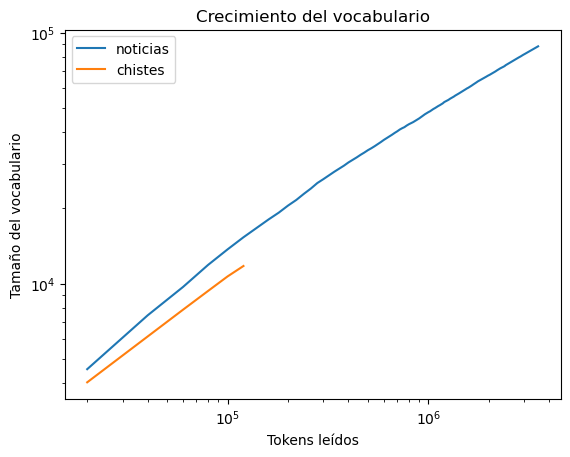

In [10]:
import matplotlib.pyplot as plt

def curva_vocabulario(tokens_por_documento: list[list[str]],
                      cada: int = 20_000) -> tuple[list[int], list[int]]:
    # Lee los tokens en orden y anota el tamaño del vocabulario
    # cada `cada` tokens
    vistos = set()
    tokens_leidos, tamanos_vocabulario = [], []
    n = 0
    for tokens in tokens_por_documento:
        for token in tokens:
            vistos.add(token)
            n += 1
            if n % cada == 0:
                tokens_leidos.append(n)
                tamanos_vocabulario.append(len(vistos))
    return tokens_leidos, tamanos_vocabulario


for nombre, tokens in [("noticias", tokens_noticias),
                       ("chistes", tokens_chistes)]:
    x, y = curva_vocabulario(tokens)
    plt.plot(x, y, label=nombre)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tokens leídos")
plt.ylabel("Tamaño del vocabulario")
plt.title("Crecimiento del vocabulario")
plt.legend()
plt.show()

En escala logarítmica en ambos ejes, las curvas son casi rectas. Eso quiere decir que el vocabulario crece como una potencia del número de tokens, con un exponente menor que 1: si el corpus se hace diez veces más largo, el vocabulario crece bastante menos de diez veces. Es la **ley de Heaps**, que el lingüista Gustav Herdan describió en 1960 y Harold Heaps, desde la recuperación de información, en 1978.

Noten también que, para un mismo número de tokens, los chistes tienen menos tipos que las noticias: su curva queda por debajo.

## 4. ¿Qué palabras se repiten más?

En la presentación les pedimos una predicción: ¿cuántas veces más aparece la palabra más frecuente del corpus que la décima? Veamos las diez primeras de las noticias.

In [11]:
diez_primeras = frecuencias_noticias.most_common(10)
for rango, (palabra, frecuencia) in enumerate(diez_primeras, start=1):
    print(f"{rango:2d}  {palabra:<6} {frecuencia:6d}")

f_1 = diez_primeras[0][1]
f_10 = diez_primeras[9][1]
print(f"\nf(1) / f(10) = {f_1 / f_10:.1f}")

 1  de     233220
 2  la     134774
 3  que    123272
 4  en     109441
 5  el     104855
 6  y       80264
 7  a       75777
 8  los     59838
 9  un      42774
10  se      40363

f(1) / f(10) = 5.8


El lingüista George Kingsley Zipf describió en sus libros de 1935 y 1949 una regularidad: si se ordenan las palabras de un texto de la más frecuente a la menos frecuente, la frecuencia de cada una es aproximadamente inversamente proporcional a su posición en la lista, su **rango** $r$:

$$f(r) \approx \frac{f(1)}{r}$$

La segunda palabra aparece la mitad de veces que la primera, la tercera un tercio, y la décima un décimo. La **ley de Zipf** predice entonces $f(1)/f(10) \approx 10$. En las noticias la razón es 5,8. La ley es una aproximación: acierta el orden de magnitud, y el gráfico de más abajo muestra dónde se aleja.

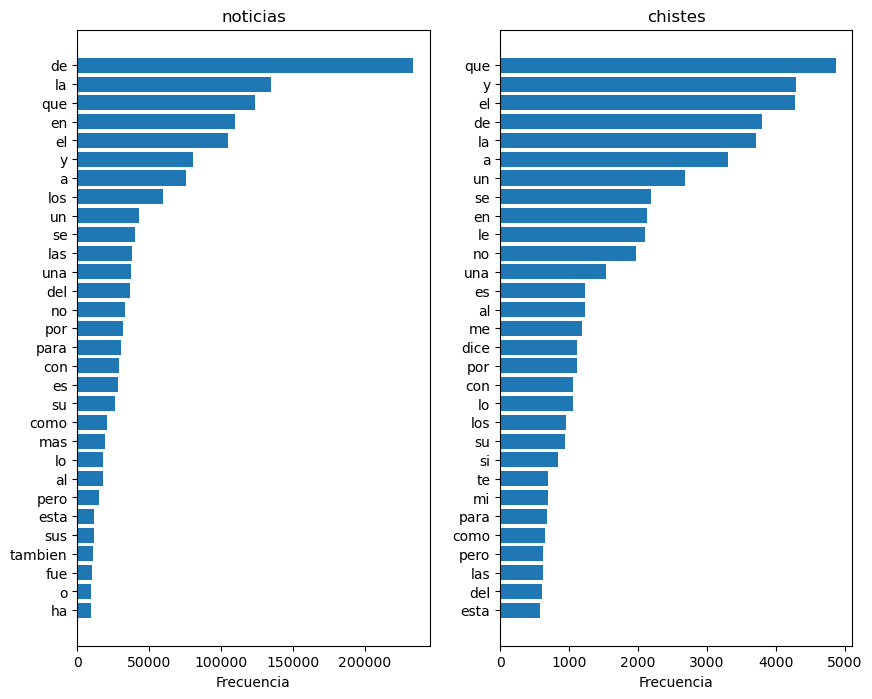

In [12]:
fig, axs = plt.subplots(ncols=2, figsize=(10, 8))
for ax, nombre, frecuencias in [(axs[0], "noticias", frecuencias_noticias),
                                (axs[1], "chistes", frecuencias_chistes)]:
    treinta_primeras = frecuencias.most_common(30)
    ax.barh([palabra for palabra, f in treinta_primeras],
            [f for palabra, f in treinta_primeras])
    ax.invert_yaxis()
    ax.set_title(nombre)
    ax.set_xlabel("Frecuencia")
plt.show()

Las barras caen muy rápido y después se aplanan. Comparemos esa caída con la de Zipf: la frecuencia de las 100 palabras más frecuentes de las noticias contra su rango, con la curva $f(1)/r$ punteada.

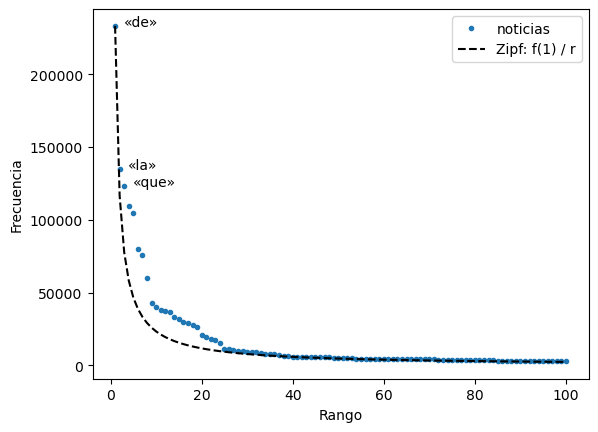

In [13]:
cien_primeras = frecuencias_noticias.most_common(100)
rangos_100 = range(1, 101)
f_1 = cien_primeras[0][1]

plt.plot(rangos_100, [f for palabra, f in cien_primeras], "o",
         markersize=3, label="noticias")
plt.plot(rangos_100, [f_1 / r for r in rangos_100], "k--",
         label="Zipf: f(1) / r")
for rango, (palabra, f) in enumerate(cien_primeras[:3], start=1):
    plt.annotate(f"«{palabra}»", (rango, f), xytext=(6, 0),
                 textcoords="offset points")
plt.xlabel("Rango")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

Las dos curvas tienen la misma forma: una caída brusca en las primeras palabras y una cola larga y casi plana. Pero aquí vemos solo 100 de las 88.314 palabras del vocabulario, y desde el rango 40 los puntos ya se confunden con el eje. Para ver todo el vocabulario se grafica en escala logarítmica en ambos ejes, donde $f(1)/r$ se vuelve una recta de pendiente $-1$, la línea punteada.

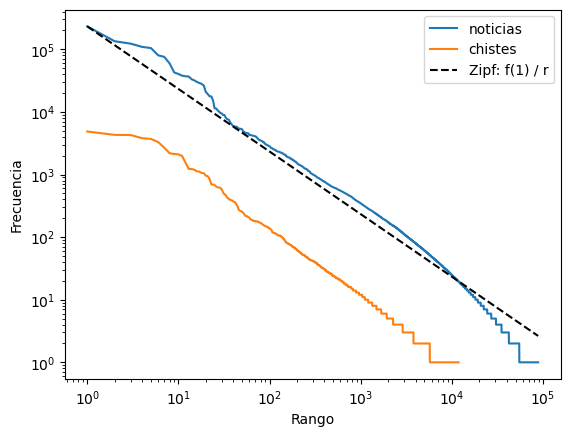

In [14]:
frecuencias_ordenadas = sorted(frecuencias_noticias.values(), reverse=True)
rangos = range(1, len(frecuencias_ordenadas) + 1)

plt.plot(rangos, frecuencias_ordenadas, label="noticias")
plt.plot(range(1, len(frecuencias_chistes) + 1),
         sorted(frecuencias_chistes.values(), reverse=True), label="chistes")
plt.plot(rangos, [frecuencias_ordenadas[0] / r for r in rangos], "k--",
         label="Zipf: f(1) / r")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Rango")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

Entre los rangos 2 y 30, la curva de las noticias va por encima de la recta: después de «de», las palabras más frecuentes caen más lento que $1/r$. Por eso $f(1)/f(10)$ dio 5,8 y no 10.

En el extremo derecho está la otra cara de la ley: una cola larga de palabras que aparecen muy pocas veces. ¿Cuántas aparecen una sola vez?

In [15]:
una_vez = [p for p, f in frecuencias_noticias.items() if f == 1]
n_tipos = len(frecuencias_noticias)
print(f"Tipos que aparecen una sola vez: {len(una_vez)} de {n_tipos} "
      f"({len(una_vez) / n_tipos:.0%})")
una_vez[:10]

Tipos que aparecen una sola vez: 33501 de 88314 (38%)


['pma',
 'lanzarles',
 'lideraran',
 'horrorizar',
 'internaron',
 'grimm',
 'embellecerla',
 'colorin',
 'recriminacion',
 'despotica']

Más de un tercio del vocabulario, el 38 %, aparece una sola vez: siglas, nombres propios y formas verbales poco comunes, como «lanzarles» o «embellecerla». Por mucho texto que lea, un modelo va a ver la mayoría de las palabras muy pocas veces. Es una de las razones para cortar el texto en subpalabras, como hace BPE en el notebook 1.1.

## 5. Nubes de palabras y stopwords

Una nube de palabras dibuja cada palabra con un tamaño proporcional a su frecuencia. Es la forma más común de mostrar de qué habla un corpus. Con lo que acabamos de ver, ¿qué palabras van a quedar más grandes?

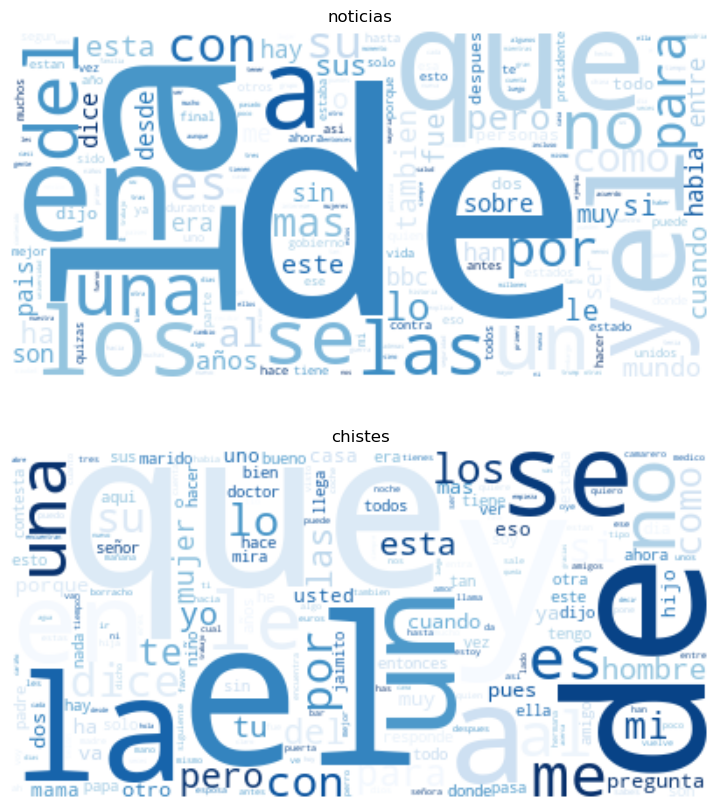

In [16]:
import wordcloud

nube = wordcloud.WordCloud(background_color="white", colormap="Blues")

fig, axs = plt.subplots(nrows=2, figsize=(10, 10))
for ax, nombre, frecuencias in [(axs[0], "noticias", frecuencias_noticias),
                                (axs[1], "chistes", frecuencias_chistes)]:
    ax.imshow(nube.generate_from_frequencies(frecuencias),
              interpolation="bilinear")
    ax.set_title(nombre)
    ax.axis("off")
plt.show()

Las dos nubes se parecen: las dominan artículos, preposiciones y conjunciones, que aparecen en cualquier texto. Estas palabras se llaman **stopwords** y se suelen filtrar con una lista. spaCy trae una para el español. Como nuestro texto no tiene tildes, normalizamos también la lista.

Ojo con filtrar a ciegas: en «no me gusta», quitar «no» y «me» deja «gusta». Para clasificar opiniones, la negación importa.

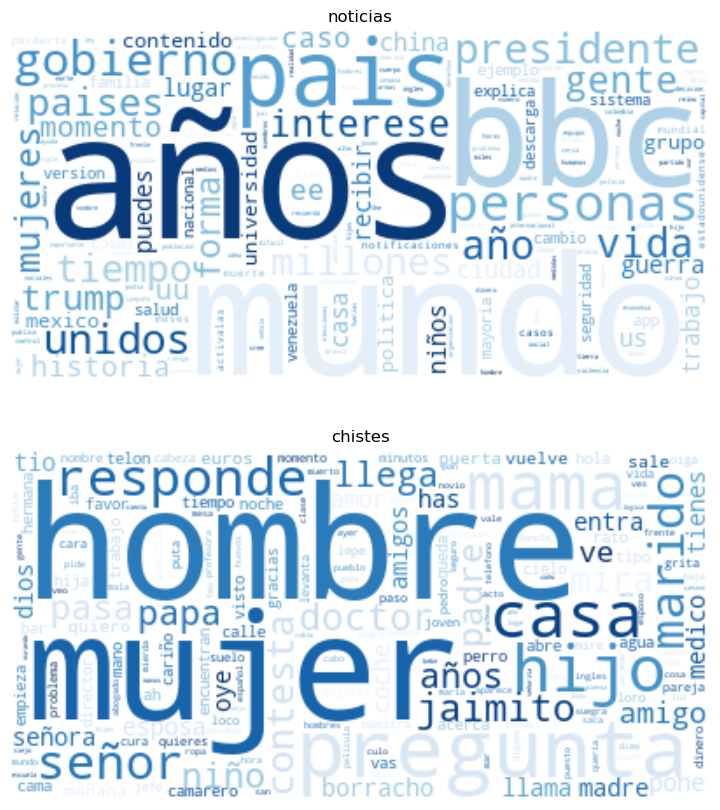

In [17]:
import spacy.lang.es

stopwords = {normalize(p).strip() for p in spacy.lang.es.stop_words.STOP_WORDS}

fig, axs = plt.subplots(nrows=2, figsize=(10, 10))
for ax, nombre, frecuencias in [(axs[0], "noticias", frecuencias_noticias),
                                (axs[1], "chistes", frecuencias_chistes)]:
    sin_stopwords = {p: f for p, f in frecuencias.items()
                     if p not in stopwords}
    ax.imshow(nube.generate_from_frequencies(sin_stopwords),
              interpolation="bilinear")
    ax.set_title(nombre)
    ax.axis("off")
plt.show()

Cada dominio tiene además sus propias palabras vacías. En las noticias, «dijo» y «años» aparecen en casi todas y no dicen de qué trata ninguna, y «bbc» y «mundo» vienen del nombre del medio. Las agregamos a la lista.

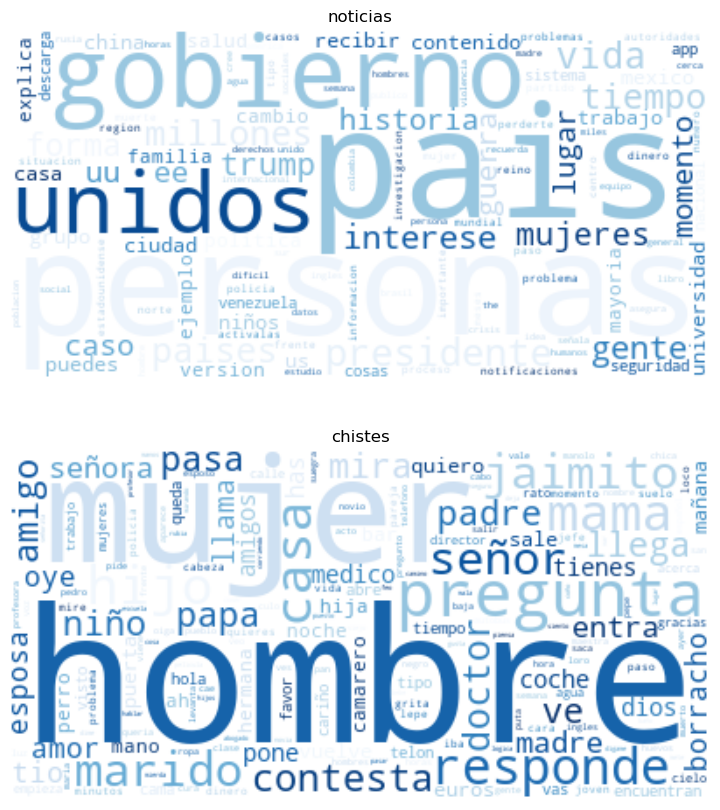

In [18]:
stopwords_extendidas = stopwords | {"dijo", "años", "año", "bbc", "mundo"}

fig, axs = plt.subplots(nrows=2, figsize=(10, 10))
for ax, nombre, frecuencias in [(axs[0], "noticias", frecuencias_noticias),
                                (axs[1], "chistes", frecuencias_chistes)]:
    sin_stopwords = {p: f for p, f in frecuencias.items()
                     if p not in stopwords_extendidas}
    ax.imshow(nube.generate_from_frequencies(sin_stopwords),
              interpolation="bilinear")
    ax.set_title(nombre)
    ax.axis("off")
plt.show()

Ahora las nubes muestran de qué habla cada corpus. En las noticias, «pais», «personas», «gobierno», «presidente», «trump» y «guerra». En los chistes, «hombre», «mujer», «pregunta», «responde», «mama» y «jaimito»: el formato de diálogo de muchos chistes. En las noticias todavía se cuelan «recibir», «notificaciones», «descarga» y «app». Su origen aparece en la sección 8.

## 6. ¿Qué palabras distinguen a un documento?

La nube resume el corpus completo. Pero si queremos saber de qué habla una sola noticia, contar sus palabras no basta: las más frecuentes de cualquier noticia siguen siendo «de», «la» y «el». La lista de stopwords es un parche hecho a mano. ¿Hay una forma de que los números mismos bajen el peso de las palabras que están en todas partes?

Karen Spärck Jones propuso una en 1972, para buscar documentos: una palabra que aparece en pocos documentos de la colección dice más sobre ellos que una que aparece en casi todos. Combinada con la frecuencia dentro del documento, esa idea es el peso **TF-IDF**. Para una palabra $t$ y un documento $d$ de una colección de $N$ documentos:

- $\text{tf}(t, d)$ (*term frequency*): cuántas veces aparece $t$ en $d$.
- $\text{df}(t)$ (*document frequency*): en cuántos documentos aparece $t$.
- $\text{idf}(t) = \log \dfrac{N}{\text{df}(t)}$ (*inverse document frequency*): vale 0 si $t$ está en todos los documentos y crece mientras más rara sea.

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t)$$

Una palabra pesa mucho en un documento si se repite en él y aparece en pocos documentos de la colección. Veámoslo primero con cuatro documentos diminutos.

In [19]:
import math

mini_corpus = [
    "la casa de mi tia es grande",
    "la casa de playa es bonita",
    "el volcan hizo erupcion cerca de la casa y la erupcion del volcan",
    "mi casa de campo es de madera",
]
mini_documentos = [documento.split() for documento in mini_corpus]
N = len(mini_documentos)

# df: en cuántos documentos aparece cada palabra. Con set() contamos
# cada palabra una sola vez por documento.
df = collections.Counter(
    itertools.chain(*[set(documento) for documento in mini_documentos])
)
idf = {palabra: math.log(N / df[palabra]) for palabra in df}

tabla_idf = pd.DataFrame({"df": df, "idf": idf}).round(2)
tabla_idf.sort_values("idf")

,df,idf
de,4,0.00
casa,4,0.00
la,3,0.29
es,3,0.29
mi,2,0.69
tia,1,1.39
grande,1,1.39
bonita,1,1.39
playa,1,1.39
hizo,1,1.39


«casa» y «de» están en los cuatro documentos: su idf es 0. Las palabras que están en un solo documento tienen el idf más alto, $\log 4 \approx 1{,}39$. Ahora multiplicamos por la frecuencia de cada palabra en su documento. ¿Cuál será la palabra con más peso del tercer documento?

In [20]:
for numero, documento in enumerate(mini_documentos, start=1):
    tf = collections.Counter(documento)
    pesos = {palabra: tf[palabra] * idf[palabra] for palabra in tf}
    mejores = sorted(pesos.items(), key=lambda par: par[1], reverse=True)[:3]
    resumen = ", ".join(f"{palabra} {peso:.2f}" for palabra, peso in mejores)
    print(f"Documento {numero}: {resumen}")

Documento 1: tia 1.39, grande 1.39, mi 0.69
Documento 2: playa 1.39, bonita 1.39, la 0.29
Documento 3: volcan 2.77, erupcion 2.77, el 1.39
Documento 4: campo 1.39, madera 1.39, mi 0.69


En el tercer documento ganan «volcan» y «erupcion»: se repiten dos veces y no aparecen en ningún otro. En los demás, las palabras de más peso son las que solo ese documento tiene.

Ahora con una noticia real: la de la bicicleta antirrobo, que vimos al principio. El df se cuenta sobre las 4.000 noticias. A la izquierda, la nube de la noticia con frecuencias. A la derecha, con pesos TF-IDF. En ninguna de las dos quitamos stopwords.

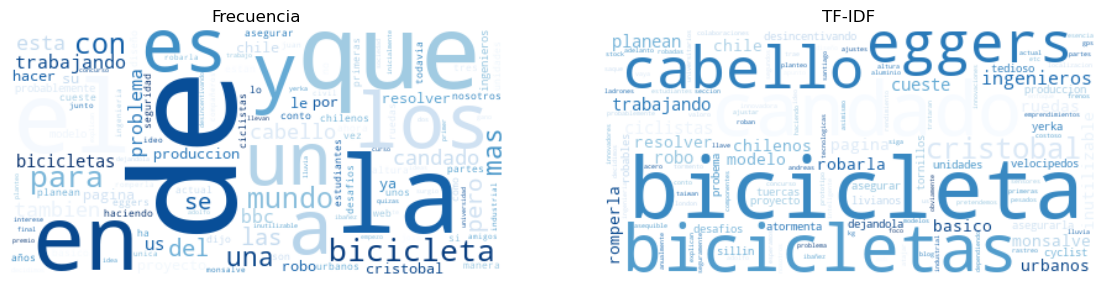

In [21]:
N_noticias = len(tokens_noticias)
df_noticias = collections.Counter(
    itertools.chain(*[set(tokens) for tokens in tokens_noticias])
)

tf_noticia = collections.Counter(tokens_noticias[1597])
tfidf_noticia = {
    palabra: tf_noticia[palabra] * math.log(N_noticias / df_noticias[palabra])
    for palabra in tf_noticia
}

fig, axs = plt.subplots(ncols=2, figsize=(14, 5))
for ax, pesos, titulo in [(axs[0], tf_noticia, "Frecuencia"),
                          (axs[1], tfidf_noticia, "TF-IDF")]:
    ax.imshow(nube.generate_from_frequencies(pesos), interpolation="bilinear")
    ax.set_title(titulo)
    ax.axis("off")
plt.show()

Con frecuencias, la nube de la noticia está hecha de «de», «la», «que» y «el», como la de cualquier otra noticia. Con TF-IDF aparecen bicicleta, candado, Cabello y Eggers (dos de los inventores): las palabras que distinguen a esta noticia de las demás. Noten también que «bicicleta» y «bicicletas» cuentan como palabras distintas, porque no lematizamos (notebook 1.1).

## 7. Una palabra en su contexto

Hasta aquí contamos palabras sueltas. Pero una misma palabra puede usarse de varias maneras. ¿Cómo se usa «banco» en las noticias: el de la plaza o el que da créditos?

Una **concordancia** o KWIC (*key word in context*) muestra cada aparición de una palabra con algunas palabras a cada lado.

In [22]:
def concordancia(tokens_por_documento: list[list[str]], palabra: str,
                 ventana: int = 5, max_resultados: int = 10) -> list[str]:
    # Cada aparición de `palabra`, con `ventana` palabras a cada lado
    resultados = []
    for tokens in tokens_por_documento:
        for i, token in enumerate(tokens):
            if token == palabra:
                izquierda = " ".join(tokens[max(0, i - ventana):i])
                derecha = " ".join(tokens[i + 1:i + 1 + ventana])
                resultados.append(f"{izquierda:>40} [{token}] {derecha}")
                if len(resultados) == max_resultados:
                    return resultados
    return resultados


for linea in concordancia(tokens_noticias, "banco"):
    print(linea)

             con intereses muy altos del [banco] esperas poderlo pagar pero sabes
              pistola a una sucursal del [banco] cic en el distrito de
              su informe mas reciente el [banco] central reporto que en mayo
                     una señal de que el [banco] podria incurrir en medidas de
               en granito una especie de [banco] de conocimiento al aire libre
                   al en segun datos del [banco] mundial esta es una de
                 un problema de la mujer [banco] de ovulos un embrion con
              sampaoli vuelve a mover el [banco] y entra christian pavon en
                 vez haciendo fila en un [banco] o no se donde un
                    a actuar mas como un [banco] que como una tecnologica un


En las noticias, «banco» aparece con varios sentidos: el que da créditos («banco central», «banco mundial»), un banco de óvulos, un banco de conocimiento y, en una noticia de fútbol, el banco de suplentes («sampaoli vuelve a mover el banco»). Al contar palabras sueltas, todos esos usos suman a la misma palabra. La concordancia los separa porque muestra el contexto. Una forma con varios sentidos es un caso de **polisemia**.

## 8. ¿Qué palabras van juntas?

Algunas palabras aparecen juntas mucho más de lo que esperaríamos por azar: «banco central», «inteligencia artificial», «derechos humanos». Estas combinaciones se llaman **colocaciones**. Para encontrarlas contamos **bigramas**, pares de palabras consecutivas. En «el perro mordió al otro perro» los bigramas son «el perro», «perro mordió», «mordió al», «al otro» y «otro perro». En general, una secuencia de $n$ palabras consecutivas es un **n-grama**.

Si contamos bigramas directamente, ganan «de la» y «en el». Por eso quitamos antes las stopwords.

In [23]:
bigramas_noticias = collections.Counter()
for tokens in tokens_noticias:
    sin_stopwords = [t for t in tokens if t not in stopwords_extendidas]
    bigramas_noticias.update(zip(sin_stopwords, sin_stopwords[1:]))

bigramas_noticias.most_common(20)

[(('ee', 'uu'), 2187),
 (('puedes', 'recibir'), 1464),
 (('recibir', 'notificaciones'), 1464),
 (('perderte', 'contenido'), 1462),
 (('app', 'activalas'), 1430),
 (('activalas', 'perderte'), 1430),
 (('descarga', 'version'), 1211),
 (('version', 'app'), 1210),
 (('reino', 'unido'), 1153),
 (('us', 'millones'), 1018),
 (('notificaciones', 'descarga'), 768),
 (('notificaciones', 'news'), 686),
 (('news', 'descarga'), 686),
 (('america', 'latina'), 656),
 (('redes', 'sociales'), 526),
 (('derechos', 'humanos'), 510),
 (('donald', 'trump'), 503),
 (('corea', 'norte'), 438),
 (('casa', 'blanca'), 393),
 (('siglas', 'ingles'), 390)]

Aparecen colocaciones conocidas: «reino unido», «america latina», «redes sociales», «derechos humanos», «donald trump», y «ee uu», que es «EE. UU.» después de normalizar. Pero varios de los primeros puestos son extraños: «puedes recibir», «recibir notificaciones», «activalas perderte». Vienen de una frase que BBC Mundo agrega al final de muchas noticias: «Ahora puedes recibir notificaciones de BBC Mundo. Descarga la nueva versión de nuestra app y actívalas para no perderte nuestro mejor contenido.» ¿En cuántas noticias está?

In [24]:
con_la_frase = [texto for texto in noticias["text"]
                if "puedes recibir notificaciones" in texto]
print(f"{len(con_la_frase)} de {len(noticias)} noticias")

1460 de 4000 noticias


Más de un tercio de las noticias termina con esa frase, y un modelo entrenado con este corpus la aprendería como si fuera parte de las noticias. Encontrar ruido de este tipo antes de entrenar es una de las razones para explorar un corpus.

La concordancia y los bigramas miran lo mismo desde dos lados: la compañía de una palabra. El lingüista J. R. Firth lo resumió en 1957: «You shall know a word by the company it keeps!» (¡Conocerás una palabra por la compañía que mantiene!). La próxima clase convertimos esa idea en números.

## Resumen

- Un corpus se describe por su número de documentos, de tokens y de tipos. La diversidad léxica (tipos / tokens) solo se compara entre corpus de tamaño parecido, porque baja a medida que el corpus crece.
- Ley de Heaps: el vocabulario crece como una potencia del número de tokens, con exponente menor que 1.
- Ley de Zipf: la frecuencia de una palabra es aproximadamente inversamente proporcional a su rango. Pocas palabras se llevan buena parte del texto y muchas aparecen una sola vez.
- Las nubes de palabras muestran frecuencias. Sin filtrar stopwords, todas las nubes se parecen.
- TF-IDF pesa cada palabra de un documento por su frecuencia en él y por lo rara que es en la colección. Destaca las palabras distintivas sin una lista de stopwords.
- La concordancia muestra una palabra en sus contextos. Los bigramas muestran qué palabras van juntas.
- Explorar también encuentra ruido, como la frase que BBC Mundo repite al final de más de un tercio de sus noticias.

## Lecturas

- Jurafsky y Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), 3.ª ed. (borrador), cap. 2, «Words and Tokens»: tipos, tokens, corpus y la ley de Herdan y Heaps.
- Manning, Raghavan y Schütze, [*Introduction to Information Retrieval*](https://nlp.stanford.edu/IR-book/) (2008): §5.1 para las leyes de Heaps y Zipf, §6.2 para tf e idf.

## Ejercicios

### Ejercicio 1

Usa la concordancia para ver cómo se usa la palabra «doctor» en el corpus de chistes. ¿Qué patrón se repite?

<details><summary>Solución</summary>

```python
for linea in concordancia(tokens_chistes, "doctor", ventana=6):
    print(linea)
```

</details>

### Ejercicio 2

Obtén los 10 bigramas más frecuentes de los chistes, sin stopwords. ¿Qué colocaciones típicas del humor aparecen?

<details><summary>Solución</summary>

```python
bigramas_chistes = collections.Counter()
for tokens in tokens_chistes:
    sin_stopwords = [t for t in tokens if t not in stopwords_extendidas]
    bigramas_chistes.update(zip(sin_stopwords, sin_stopwords[1:]))

bigramas_chistes.most_common(10)
```

</details>

### Ejercicio 3

Repite el experimento de la sección 3 con el corpus de chistes. ¿Su diversidad léxica cae igual que la de las noticias?

<details><summary>Solución</summary>

```python
for n_documentos in [100, 500, 1000, len(tokens_chistes)]:
    frecuencias = collections.Counter(
        itertools.chain(*tokens_chistes[:n_documentos])
    )
    ttr = len(frecuencias) / sum(frecuencias.values())
    print(f"documentos: {n_documentos:5d}   diversidad léxica: {ttr:.3f}")
```

</details>